In [1]:
import os
os.environ["DATA_ROOT"] = r"C:\Users\ASUS F15\Downloads\enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch"

In [2]:
import os, io, glob, time, random, hashlib, warnings
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import cv2

warnings.filterwarnings("ignore")

# ----------------------------- run switches -----------------------------
SEED = 42
DEBUG_SUBSET = 3000        # e.g. 3000 -> use only 3000 training images (smoke test)
RUN_FULL_AUDIT = False      # hash/decode/blur-check every image (a few minutes, cached to disk)
# -------------------------------------------------------------------------

random.seed(SEED)
np.random.seed(SEED)
WORK = "/kaggle/working" if os.path.isdir("/kaggle/working") else "."


def find_data_root():
    env = os.environ.get("DATA_ROOT")
    if env:
        return env
    hits = glob.glob("/kaggle/input/*/train_labels.csv") + glob.glob("/kaggle/input/*/*/train_labels.csv")
    if not hits:
        raise FileNotFoundError("train_labels.csv not found under /kaggle/input - add the competition data to the notebook.")
    return os.path.dirname(hits[0])


def find_img_dir(split):
    for cand in (f"{DATA_ROOT}/{split}/{split}", f"{DATA_ROOT}/{split}"):
        if os.path.exists(f"{cand}/00001.jpg"):
            return cand
    raise FileNotFoundError(f"Could not find 00001.jpg for split '{split}' under {DATA_ROOT}")


DATA_ROOT = find_data_root()
TRAIN_DIR, TEST_DIR = find_img_dir("train"), find_img_dir("test")
TRAIN_CSV = f"{DATA_ROOT}/train_labels.csv"
SAMPLE_SUB = f"{DATA_ROOT}/sample_submission.csv"
print("data root :", DATA_ROOT)
print("train dir :", TRAIN_DIR)
print("test dir  :", TEST_DIR)

# image_id is read as TEXT so '00001' keeps its zero padding (pandas would turn it into 1)
labels_df = pd.read_csv(TRAIN_CSV, dtype={"image_id": str})
labels_df["image_id"] = labels_df["image_id"].str.zfill(5)
sub_template = pd.read_csv(SAMPLE_SUB)          # image_id stays an integer here, exactly as Kaggle expects it back

CLASSES = sorted(labels_df["class"].unique())
CLS2IDX = {c: i for i, c in enumerate(CLASSES)}
labels_df["y"] = labels_df["class"].map(CLS2IDX)
labels_df["species"] = labels_df["class"].str[:3]       # Cat / Dog
labels_df["part"] = labels_df["class"].str[3:]          # Eye / Face / Mouth / Nose
labels_df["path"] = TRAIN_DIR + "/" + labels_df["image_id"] + ".jpg"
test_ids = sub_template["image_id"].tolist()
test_paths = [f"{TEST_DIR}/{str(i).zfill(5)}.jpg" for i in test_ids]

if DEBUG_SUBSET:
    labels_df = labels_df.sample(DEBUG_SUBSET, random_state=SEED).reset_index(drop=True)

print(f"\n{len(CLASSES)} classes: {CLASSES}")
print(f"train images: {len(labels_df):,}   test images: {len(test_paths):,}")
print("submission columns:", list(sub_template.columns))

data root : C:\Users\ASUS F15\Downloads\enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch
train dir : C:\Users\ASUS F15\Downloads\enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch/train/train
test dir  : C:\Users\ASUS F15\Downloads\enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch/test/test

8 classes: ['CatEye', 'CatFace', 'CatMouth', 'CatNose', 'DogEye', 'DogFace', 'DogMouth', 'DogNose']
train images: 3,000   test images: 29,443
submission columns: ['image_id', 'class']


          images  percent
class                    
CatEye       642    21.40
CatFace      331    11.03
CatMouth     355    11.83
CatNose      313    10.43
DogEye       535    17.83
DogFace      256     8.53
DogMouth     290     9.67
DogNose      278     9.27

largest / smallest class ratio: 2.51


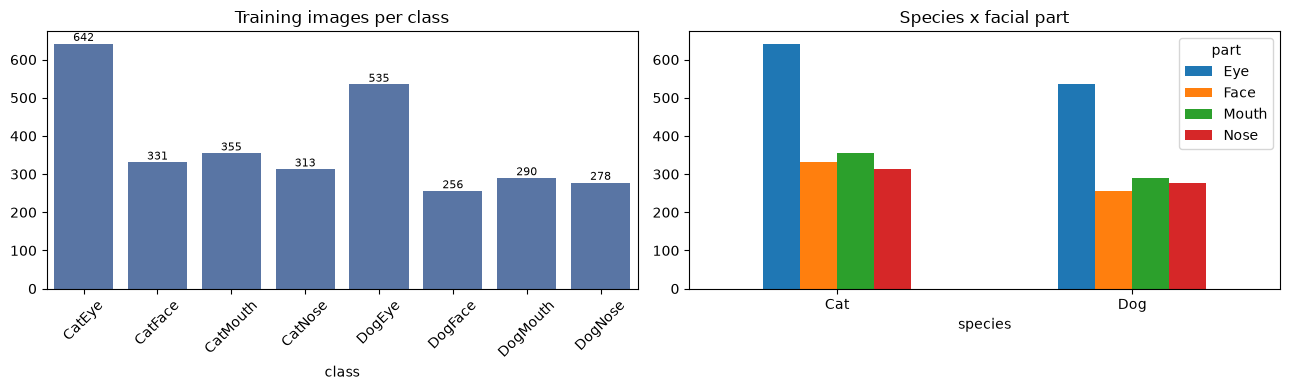

In [3]:
counts = labels_df["class"].value_counts().sort_index()
summary = pd.DataFrame({"images": counts, "percent": (100 * counts / counts.sum()).round(2)})
print(summary)
print(f"\nlargest / smallest class ratio: {counts.max() / counts.min():.2f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.barplot(x=counts.index, y=counts.values, ax=ax[0], color="#4C72B0")
ax[0].set_title("Training images per class"); ax[0].tick_params(axis="x", rotation=45)
for i, v in enumerate(counts.values):
    ax[0].text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=8)
pd.crosstab(labels_df["species"], labels_df["part"]).plot(kind="bar", ax=ax[1], rot=0)
ax[1].set_title("Species x facial part")
plt.tight_layout(); plt.show()

sample_submission placeholder class distribution (NOT the true test labels):
class
CatEye      4567
CatFace     3571
CatMouth    3570
CatNose     3457
DogEye      4221
DogFace     3407
DogMouth    3341
DogNose     3309
Name: count, dtype: int64


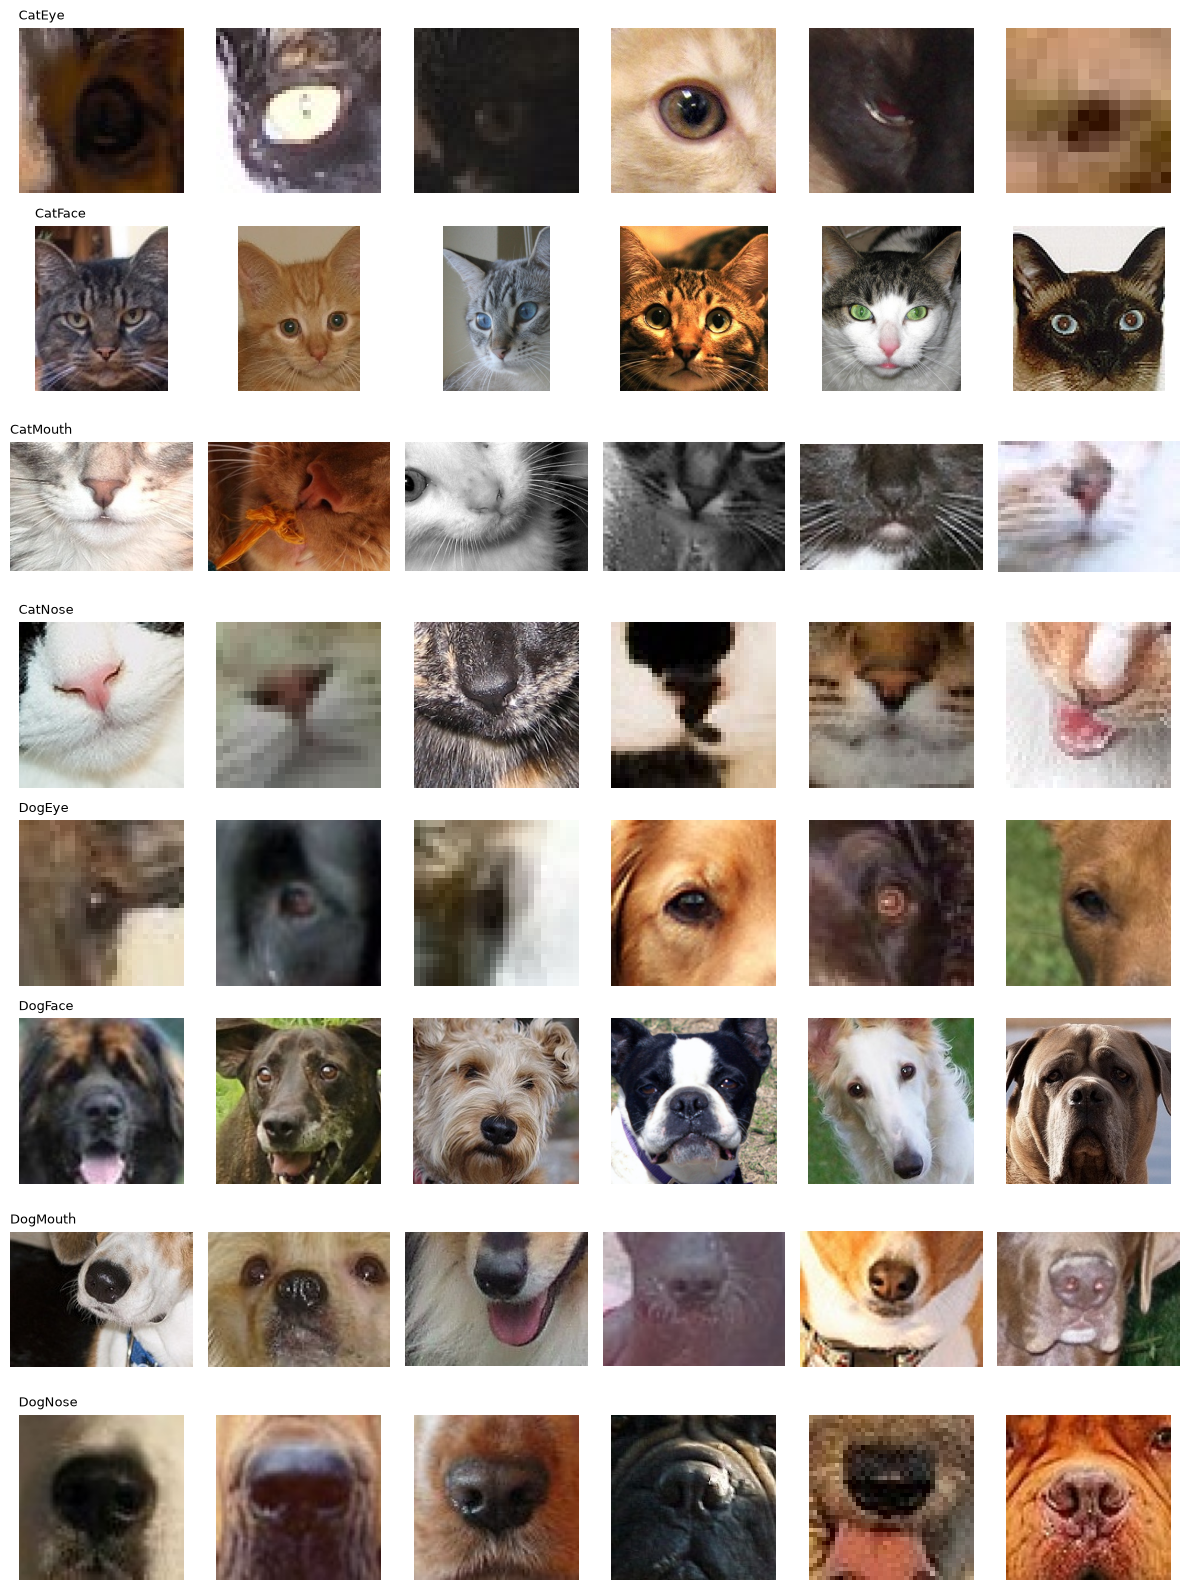

In [4]:
print("sample_submission placeholder class distribution (NOT the true test labels):")
print(sub_template["class"].value_counts().sort_index())

# 6 random examples of every class
fig, axes = plt.subplots(len(CLASSES), 6, figsize=(12, 2 * len(CLASSES)))
rng = np.random.RandomState(SEED)
for r, c in enumerate(CLASSES):
    sel = labels_df[labels_df["class"] == c].sample(6, random_state=rng)
    for k, p in enumerate(sel["path"]):
        axes[r, k].imshow(Image.open(p).convert("RGB")); axes[r, k].axis("off")
    axes[r, 0].set_title(c, fontsize=9, loc="left")
plt.tight_layout(); plt.show()

In [5]:
AUDIT_CSV = f"{WORK}/image_audit.csv"


def audit_one(item):
    split, image_id, path = item
    try:
        with open(path, "rb") as f:
            raw = f.read()
        im = Image.open(io.BytesIO(raw)); im.load()
        gray = np.asarray(im.convert("L"))
        blur = float(cv2.Laplacian(gray, cv2.CV_64F).var())
        return (split, image_id, im.size[0], im.size[1], im.mode, hashlib.md5(raw).hexdigest(), blur, len(raw), 1)
    except Exception:
        return (split, image_id, 0, 0, "ERR", None, np.nan, 0, 0)


audit = None
if RUN_FULL_AUDIT:
    if os.path.exists(AUDIT_CSV) and not DEBUG_SUBSET:
        audit = pd.read_csv(AUDIT_CSV, dtype={"image_id": str})
    else:
        items = [("train", r.image_id, r.path) for r in labels_df.itertuples()]
        items += [("test", str(i).zfill(5), p) for i, p in zip(test_ids, test_paths)]
        t0 = time.time()
        with ThreadPoolExecutor(8) as ex:
            rows = list(ex.map(audit_one, items, chunksize=256))
        audit = pd.DataFrame(rows, columns=["split", "image_id", "w", "h", "mode", "md5", "blur", "bytes", "ok"])
        if not DEBUG_SUBSET:
            audit.to_csv(AUDIT_CSV, index=False)
        print(f"audited {len(audit):,} files in {time.time() - t0:.0f}s")

if audit is not None:
    tr_a = audit[audit["split"] == "train"].merge(labels_df[["image_id", "class", "part", "y"]], on="image_id")
    te_a = audit[audit["split"] == "test"]
    print("corrupted / unreadable  train:", int((tr_a["ok"] == 0).sum()), " test:", int((te_a["ok"] == 0).sum()))
    print("image modes (train):", tr_a["mode"].value_counts().to_dict())

    ok = tr_a[tr_a["ok"] == 1].copy()
    ok["min_side"] = ok[["w", "h"]].min(axis=1)
    ok["aspect"] = ok["w"] / ok["h"]
    print("\nwidth / height / shorter side (train):")
    print(ok[["w", "h", "min_side"]].describe().round(1).T[["min", "25%", "50%", "75%", "max"]])
    print("\nmedian size per class:")
    print(ok.groupby("class")[["w", "h"]].median())
    print(f"images with shorter side < 64 px: {(ok['min_side'] < 64).mean():.1%}")
    print(f"images that are not square (aspect outside 0.95-1.05): {((ok['aspect'] < 0.95) | (ok['aspect'] > 1.05)).mean():.1%}")

    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    sns.boxplot(data=ok, x="class", y="min_side", ax=ax[0], showfliers=False)
    ax[0].set_title("Shorter image side (px) per class"); ax[0].tick_params(axis="x", rotation=45)
    ax[1].hist(ok["min_side"].clip(upper=400), bins=60); ax[1].set_title("Shorter side distribution (clipped at 400 px)")
    plt.tight_layout(); plt.show()

    # exact duplicates
    dup_in_train = tr_a["md5"].duplicated(keep=False) & tr_a["md5"].notna()
    conflict = tr_a[dup_in_train].groupby("md5")["class"].nunique()
    print(f"\nexact-duplicate train images: {int(dup_in_train.sum()):,} "
          f"({tr_a.loc[dup_in_train, 'md5'].nunique():,} groups); groups with CONFLICTING labels: {int((conflict > 1).sum())}")
    overlap = set(tr_a["md5"].dropna()) & set(te_a["md5"].dropna())
    print(f"test images whose bytes also appear in train: {te_a['md5'].isin(overlap).sum():,}")

    # blur
    thr = tr_a.groupby("class")["blur"].transform(lambda s: s.quantile(0.05))
    print("\nblurriest 5% per class (relative threshold) ->", int((tr_a["blur"] < thr).sum()), "images")
    worst = tr_a.sort_values("blur").head(12)
    fig, axes = plt.subplots(2, 6, figsize=(12, 4.4))
    for a_, r in zip(axes.ravel(), worst.itertuples()):
        a_.imshow(Image.open(f"{TRAIN_DIR}/{r.image_id}.jpg").convert("RGB")); a_.axis("off"); a_.set_title(r.part, fontsize=8)
    plt.suptitle("Blurriest training images"); plt.tight_layout(); plt.show()

In [6]:
from sklearn.model_selection import StratifiedGroupKFold

df = labels_df.copy()
if audit is not None:
    bad = set(audit.loc[(audit["split"] == "train") & (audit["ok"] == 0), "image_id"])
    if bad:
        print("dropping unreadable train files:", len(bad))
        df = df[~df["image_id"].isin(bad)]
    md5_map = audit[audit["split"] == "train"].set_index("image_id")["md5"]
    groups = df["image_id"].map(md5_map).fillna(df["image_id"]).astype("category").cat.codes.values
else:
    groups = np.arange(len(df))
df = df.reset_index(drop=True)

sgkf = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=SEED)
tr_idx, va_idx = next(sgkf.split(df, df["y"], groups=groups))
train_df, val_df = df.iloc[tr_idx].reset_index(drop=True), df.iloc[va_idx].reset_index(drop=True)

assert set(groups[tr_idx]).isdisjoint(set(groups[va_idx])), "duplicate leakage between train and val!"
print(f"train: {len(train_df):,}   val: {len(val_df):,}")
print(pd.DataFrame({"train_%": (100 * train_df["class"].value_counts(normalize=True)).round(2),
                    "val_%": (100 * val_df["class"].value_counts(normalize=True)).round(2)}).sort_index())

train: 2,499   val: 501
          train_%  val_%
class                   
CatEye      21.41  21.36
CatFace     11.00  11.18
CatMouth    11.84  11.78
CatNose     10.44  10.38
DogEye      17.81  17.96
DogFace      8.56   8.38
DogMouth     9.68   9.58
DogNose      9.24   9.38


In [7]:
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision.transforms as T
from torchvision.transforms import InterpolationMode
from torch.utils.data import Dataset, DataLoader
import timm

# ----------------------------- hyper-parameters -----------------------------
MODEL_NAME = "convnext_tiny"      # alternatives: "efficientnet_b2", "resnet50", "convnext_small"
IMG_SIZE = 160
BATCH = 128
EPOCHS = 12
LR = 2e-4
WEIGHT_DECAY = 0.05
LABEL_SMOOTH = 0.1
PATIENCE = 4
NUM_WORKERS = 0 if os.name == "nt" else min(4, os.cpu_count() or 2)   # Windows notebooks need 0, Kaggle/Colab use 4
# -----------------------------------------------------------------------------

torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = True
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = dev.type == "cuda"
print("device:", dev, "| model:", MODEL_NAME, "| img:", IMG_SIZE)
if dev.type == "cpu":
    print("WARNING: no GPU found - training will be extremely slow. Enable Accelerator = GPU in the Kaggle session options.")

MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
resize = T.Resize((IMG_SIZE, IMG_SIZE), interpolation=InterpolationMode.BICUBIC)
train_tf = T.Compose([
    resize,
    T.RandomHorizontalFlip(),
    T.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.9, 1.1)),
    T.ColorJitter(0.2, 0.2, 0.2),
    T.ToTensor(), T.Normalize(MEAN, STD),
    T.RandomErasing(p=0.1, scale=(0.02, 0.08)),
])
eval_tf = T.Compose([resize, T.ToTensor(), T.Normalize(MEAN, STD)])


class FeatureDS(Dataset):
    def __init__(self, paths, labels, tf):
        self.paths, self.labels, self.tf = list(paths), labels, tf

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        x = self.tf(Image.open(self.paths[i]).convert("RGB"))
        y = int(self.labels[i]) if self.labels is not None else -1
        return x, y


def make_loader(paths, labels, tf, shuffle):
    return DataLoader(FeatureDS(paths, labels, tf), batch_size=BATCH, shuffle=shuffle, drop_last=shuffle,
                      num_workers=NUM_WORKERS, pin_memory=use_amp, persistent_workers=NUM_WORKERS > 0)


tr_dl = make_loader(train_df["path"], train_df["y"].values, train_tf, True)
va_dl = make_loader(val_df["path"], val_df["y"].values, eval_tf, False)

try:
    model = timm.create_model(MODEL_NAME, pretrained=True, num_classes=len(CLASSES), drop_rate=0.2, drop_path_rate=0.1)
except Exception as e:
    raise RuntimeError("Could not load pretrained weights. In the Kaggle sidebar set Session options -> Internet -> On "
                       "(phone verification required once), then re-run.") from e
model = model.to(dev).to(memory_format=torch.channels_last)
print(f"parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.1f} M | output classes: {len(CLASSES)}")

opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR, total_steps=EPOCHS * len(tr_dl), pct_start=0.15)
train_loss_fn = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTH)
try:
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
except (AttributeError, TypeError):
    scaler = torch.cuda.amp.GradScaler(enabled=use_amp)

device: cpu | model: convnext_tiny | img: 160


parameters: 27.8 M | output classes: 8


epoch 01/12 | train loss 1.3894 acc 0.5074 | val loss 0.6300 acc 0.7745 | 270s *best*
epoch 02/12 | train loss 0.4087 acc 0.8713 | val loss 0.2732 acc 0.9261 | 245s *best*
epoch 03/12 | train loss 0.2442 acc 0.9445 | val loss 0.2725 acc 0.9381 | 234s *best*
epoch 04/12 | train loss 0.2250 acc 0.9535 | val loss 0.1750 acc 0.9701 | 231s *best*
epoch 05/12 | train loss 0.1841 acc 0.9667 | val loss 0.2837 acc 0.9401 | 224s 
epoch 06/12 | train loss 0.1474 acc 0.9827 | val loss 0.1556 acc 0.9760 | 223s *best*
epoch 07/12 | train loss 0.1364 acc 0.9893 | val loss 0.1807 acc 0.9701 | 220s 
epoch 08/12 | train loss 0.1100 acc 0.9963 | val loss 0.1692 acc 0.9701 | 218s 
epoch 09/12 | train loss 0.1079 acc 0.9942 | val loss 0.1912 acc 0.9601 | 216s 
epoch 10/12 | train loss 0.0998 acc 0.9971 | val loss 0.1300 acc 0.9820 | 218s *best*
epoch 11/12 | train loss 0.0939 acc 0.9979 | val loss 0.1400 acc 0.9760 | 216s 
epoch 12/12 | train loss 0.0960 acc 0.9992 | val loss 0.1403 acc 0.9760 | 215s 

bes

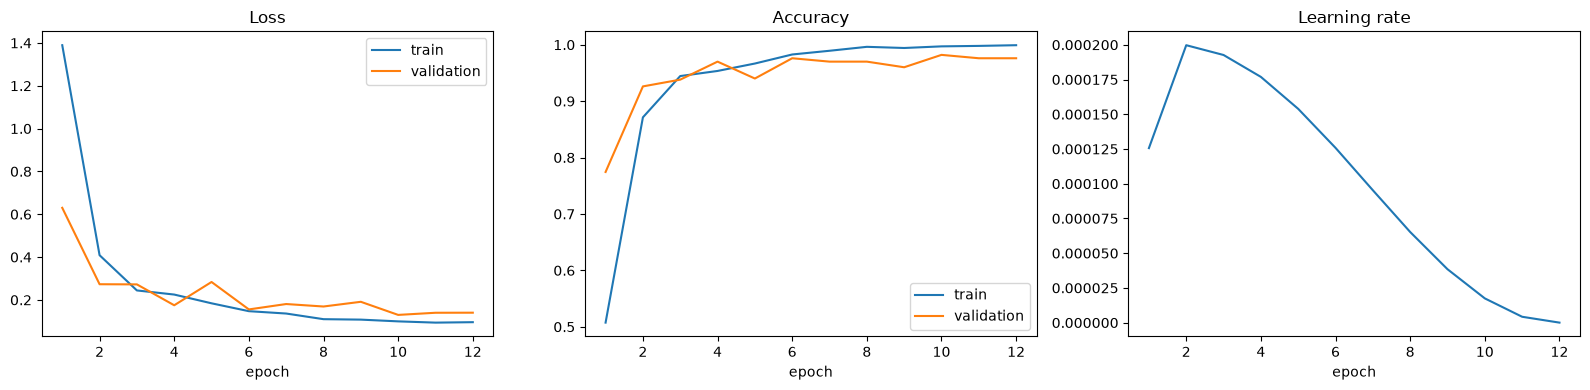

In [8]:
def run_epoch(loader, train):
    model.train(train)
    loss_sum, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x = x.to(dev, non_blocking=True).to(memory_format=torch.channels_last)
            y = y.to(dev, non_blocking=True)
            with torch.autocast(device_type=dev.type, dtype=torch.float16, enabled=use_amp):
                out = model(x)
                loss = train_loss_fn(out, y) if train else F.cross_entropy(out, y)
            if train:
                opt.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.unscale_(opt)
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(opt); scaler.update(); sched.step()
            with torch.no_grad():
                plain = F.cross_entropy(out.float(), y, reduction="sum").item()
            loss_sum += plain
            correct += (out.argmax(1) == y).sum().item()
            n += len(y)
    return loss_sum / n, correct / n


history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "lr": []}
best = {"acc": -1.0, "loss": 9e9, "epoch": -1}
BEST_PT = f"{WORK}/best_{MODEL_NAME}.pt"
bad_epochs = 0
t_start = time.time()
for ep in range(1, EPOCHS + 1):
    t0 = time.time()
    trl, tra = run_epoch(tr_dl, True)
    val, vaa = run_epoch(va_dl, False)
    for k, v in zip(history, (trl, val, tra, vaa, opt.param_groups[0]["lr"])):
        history[k].append(v)
    improved = vaa > best["acc"] or (vaa == best["acc"] and val < best["loss"])
    if improved:
        best.update(acc=vaa, loss=val, epoch=ep); bad_epochs = 0
        torch.save(model.state_dict(), BEST_PT)
    else:
        bad_epochs += 1
    print(f"epoch {ep:02d}/{EPOCHS} | train loss {trl:.4f} acc {tra:.4f} | val loss {val:.4f} acc {vaa:.4f} "
          f"| {time.time() - t0:.0f}s {'*best*' if improved else ''}")
    if bad_epochs >= PATIENCE:
        print(f"early stopping (no improvement for {PATIENCE} epochs)"); break

print(f"\nbest epoch {best['epoch']}  val acc {best['acc']:.4f}  val loss {best['loss']:.4f}  (total {(time.time() - t_start) / 60:.1f} min)")
model.load_state_dict(torch.load(BEST_PT, map_location=dev))

# learning curves
ep_axis = range(1, len(history["train_loss"]) + 1)
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(ep_axis, history["train_loss"], label="train"); ax[0].plot(ep_axis, history["val_loss"], label="validation")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(ep_axis, history["train_acc"], label="train"); ax[1].plot(ep_axis, history["val_acc"], label="validation")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
ax[2].plot(ep_axis, history["lr"]); ax[2].set_title("Learning rate"); ax[2].set_xlabel("epoch")
plt.tight_layout(); plt.savefig(f"{WORK}/learning_curves.png", dpi=150); plt.show()
pd.DataFrame(history).to_csv(f"{WORK}/history_{MODEL_NAME}.csv", index_label="epoch0")

validation accuracy (with flip TTA): 0.9820
validation log-loss                : 0.1310
validation macro-F1                : 0.9804

              precision    recall  f1-score   support

      CatEye     1.0000    0.9813    0.9906       107
     CatFace     1.0000    1.0000    1.0000        56
    CatMouth     0.9833    1.0000    0.9916        59
     CatNose     1.0000    0.9231    0.9600        52
      DogEye     0.9574    1.0000    0.9783        90
     DogFace     0.9333    1.0000    0.9655        42
    DogMouth     1.0000    0.9583    0.9787        48
     DogNose     0.9787    0.9787    0.9787        47

    accuracy                         0.9820       501
   macro avg     0.9816    0.9802    0.9804       501
weighted avg     0.9828    0.9820    0.9820       501



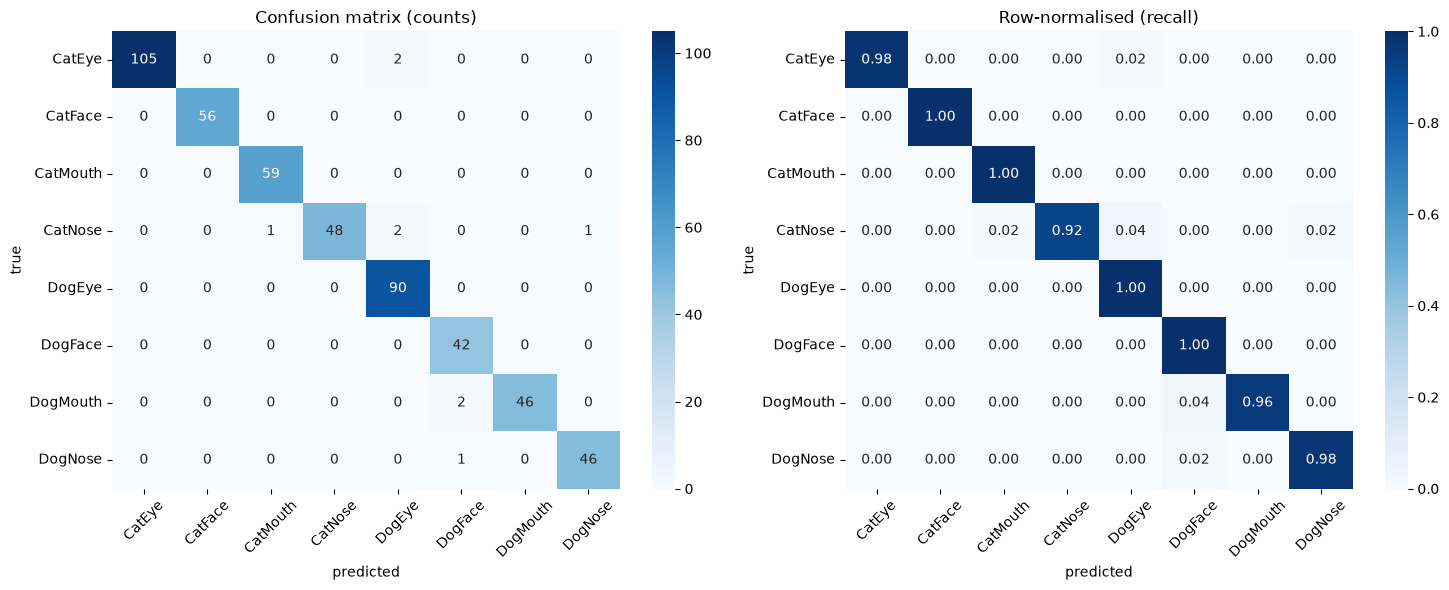

species (Cat vs Dog) accuracy: 0.9900
facial-part accuracy         : 0.9880


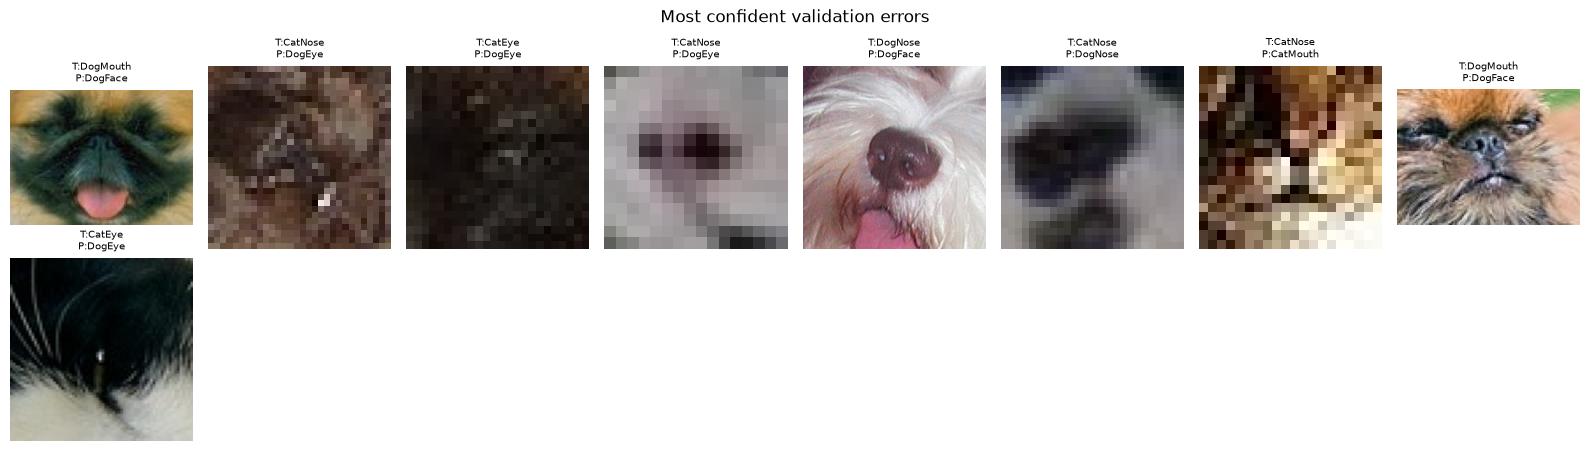

In [9]:
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score


@torch.no_grad()
def predict_probs(loader, tta=True):
    model.eval()
    out = []
    for x, _ in loader:
        x = x.to(dev, non_blocking=True).to(memory_format=torch.channels_last)
        with torch.autocast(device_type=dev.type, dtype=torch.float16, enabled=use_amp):
            p = model(x).float().softmax(1)
            if tta:
                p = (p + model(torch.flip(x, dims=[3])).float().softmax(1)) / 2
        out.append(p.cpu())
    return torch.cat(out).numpy()


val_probs = predict_probs(va_dl, tta=True)
val_pred, val_true = val_probs.argmax(1), val_df["y"].values
val_nll = float(-np.log(np.clip(val_probs[np.arange(len(val_true)), val_true], 1e-9, 1)).mean())
print(f"validation accuracy (with flip TTA): {accuracy_score(val_true, val_pred):.4f}")
print(f"validation log-loss                : {val_nll:.4f}")
print(f"validation macro-F1                : {f1_score(val_true, val_pred, average='macro'):.4f}\n")
print(classification_report(val_true, val_pred, target_names=CLASSES, digits=4))

cm = confusion_matrix(val_true, val_pred)
cm_norm = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[0]); ax[0].set_title("Confusion matrix (counts)")
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[1]); ax[1].set_title("Row-normalised (recall)")
for a_ in ax:
    a_.set_xlabel("predicted"); a_.set_ylabel("true"); a_.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.savefig(f"{WORK}/confusion_matrix.png", dpi=150); plt.show()

# Where do the mistakes come from: species or facial part?
pred_species = np.array([CLASSES[i][:3] for i in val_pred]); true_species = val_df["species"].values
pred_part = np.array([CLASSES[i][3:] for i in val_pred]); true_part = val_df["part"].values
print(f"species (Cat vs Dog) accuracy: {(pred_species == true_species).mean():.4f}")
print(f"facial-part accuracy         : {(pred_part == true_part).mean():.4f}")

# most confident mistakes
wrong = np.where(val_pred != val_true)[0]
wrong = wrong[np.argsort(-val_probs[wrong].max(1))][:16]
if len(wrong):
    fig, axes = plt.subplots(2, 8, figsize=(16, 4.6))
    for a_ in axes.ravel():
        a_.axis("off")                      # hide unused slots when there are fewer than 16 errors
    for a_, i in zip(axes.ravel(), wrong):
        a_.imshow(Image.open(val_df.loc[i, "path"]).convert("RGB"))
        a_.set_title(f"T:{CLASSES[val_true[i]]}\nP:{CLASSES[val_pred[i]]}", fontsize=7)
    plt.suptitle("Most confident validation errors"); plt.tight_layout(); plt.show()

In [10]:
te_dl = make_loader(test_paths, None, eval_tf, False)
test_probs = predict_probs(te_dl, tta=True)
np.save(f"{WORK}/test_probs_{MODEL_NAME}.npy", test_probs)
np.save(f"{WORK}/val_probs_{MODEL_NAME}.npy", val_probs)

submission = pd.DataFrame({"image_id": sub_template["image_id"].values,
                           "class": [CLASSES[i] for i in test_probs.argmax(1)]})

# format checks - these are the usual reasons for a score of 0
assert list(submission.columns) == list(sub_template.columns), "column names differ from sample_submission"
assert len(submission) == len(sub_template), "row count differs from sample_submission"
assert (submission["image_id"].values == sub_template["image_id"].values).all(), "id order differs from sample_submission"
assert submission["class"].isin(CLASSES).all() and submission["class"].notna().all(), "invalid / missing labels"
submission.to_csv(f"{WORK}/submission.csv", index=False)
print("saved", f"{WORK}/submission.csv", submission.shape)
print(submission.head())
print(submission["class"].value_counts(normalize=True).round(3).sort_index())

saved ./submission.csv (29443, 2)
   image_id     class
0         1    DogEye
1         2  DogMouth
2         3   DogNose
3         4   DogFace
4         5  CatMouth
class
CatEye      0.214
CatFace     0.106
CatMouth    0.110
CatNose     0.099
DogEye      0.189
DogFace     0.096
DogMouth    0.095
DogNose     0.091
Name: proportion, dtype: float64


In [11]:
val_files = sorted(glob.glob(f"{WORK}/val_probs_*.npy"))
if len(val_files) >= 2:
    vp = [np.load(f) for f in val_files]
    tp = [np.load(f.replace("val_probs_", "test_probs_")) for f in val_files]
    for f, p in zip(val_files, vp):
        print(f"{os.path.basename(f):40s} val acc {accuracy_score(val_true, p.argmax(1)):.4f}")
    ens_val = np.mean(vp, axis=0)
    print(f"{'ENSEMBLE':40s} val acc {accuracy_score(val_true, ens_val.argmax(1)):.4f}")
    # only overwrite the submission if the ensemble is really better on validation
    if accuracy_score(val_true, ens_val.argmax(1)) > max(accuracy_score(val_true, p.argmax(1)) for p in vp):
        ens_test = np.mean(tp, axis=0)
        sub_ens = pd.DataFrame({"image_id": sub_template["image_id"].values, "class": [CLASSES[i] for i in ens_test.argmax(1)]})
        assert len(sub_ens) == len(sub_template) and sub_ens["class"].isin(CLASSES).all()
        sub_ens.to_csv(f"{WORK}/submission.csv", index=False)
        print("ensemble is better -> submission.csv overwritten with the ensemble predictions")
    else:
        print("ensemble did not beat the best single model -> submission.csv left unchanged")
else:
    print("Train at least two different models (change MODEL_NAME and re-run) to build an ensemble.")

Train at least two different models (change MODEL_NAME and re-run) to build an ensemble.
